# Notebook 01: Source Verification & Product Catalogue Audit
**Course:** 23CSE452 Business Analytics Capstone — Review 2  
**Team Members:** Leena Sri K, Sanhitha Reddy, Kanish Kumaran M, Taraka Srinivas, Ajay N Mukunth  
**Objective:** Ingest, inspect, and rigorously validate the raw and clean Blinkit product catalogues. Verify data hygiene, absence of missing values, and legal pricing constraints (Selling Price <= MRP).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
print('Libraries successfully imported.')

Libraries successfully imported.


## 1. Load Clean Product Catalogue

In [2]:
csv_path = '../data/processed/product_catalogue/cleaned_product_catalogue.csv'
if not os.path.exists(csv_path):
    csv_path = '../../data_pipeline/cleaned_product_catalogue.csv'

df = pd.read_csv(csv_path)
print(f'Successfully loaded catalogue with {len(df)} SKUs and {len(df.columns)} attributes.')
df.head(6)

Successfully loaded catalogue with 609 SKUs and 22 attributes.


,source_name,source_product_id,product_name,category,subcategory,source_l0_category,source_l1_category,brand,raw_variant,pack_size,...,original_price,discount_pct,inventory,availability_status,rating,product_url,source_page_url,collection_date,collection_timestamp,geographic_coverage
0,Blinkit,19512,Amul Taaza Toned Milk,Dairy,Milk,Dairy,Toned Milk,Amul,500 ml,500.0,...,30,0.0,50,available,4.6,https://blinkit.com/prn/amul-taaza-toned-milk/...,https://blinkit.com/cn/milk/cid/14/922,2026-10-18,2026-10-18 01:42:05,India (National Catalog Default / Express Serv...
1,Blinkit,561270,Amul Taaza Toned Milk,Dairy,Milk,Dairy,Toned Milk,Amul,1 ltr,1.0,...,59,0.0,50,available,4.6,https://blinkit.com/prn/amul-taaza-toned-milk/...,https://blinkit.com/cn/milk/cid/14/922,2026-10-18,2026-10-18 01:42:05,India (National Catalog Default / Express Serv...
2,Blinkit,12872,Amul Gold Full Cream Milk,Dairy,Milk,Dairy,Full Cream Milk,Amul,500 ml,500.0,...,36,0.0,19,available,4.7,https://blinkit.com/prn/amul-gold-full-cream-m...,https://blinkit.com/cn/milk/cid/14/922,2026-10-18,2026-10-18 01:42:05,India (National Catalog Default / Express Serv...
3,Blinkit,561268,Amul Gold Full Cream Milk,Dairy,Milk,Dairy,Full Cream Milk,Amul,1 ltr,1.0,...,72,0.0,50,available,4.7,https://blinkit.com/prn/amul-gold-full-cream-m...,https://blinkit.com/cn/milk/cid/14/922,2026-10-18,2026-10-18 01:42:05,India (National Catalog Default / Express Serv...
4,Blinkit,160704,Amul Cow Milk,Dairy,Milk,Dairy,Cow Milk,Amul,500 ml,500.0,...,31,0.0,50,available,4.6,https://blinkit.com/prn/amul-cow-milk/prid/160704,https://blinkit.com/cn/milk/cid/14/922,2026-10-18,2026-10-18 01:42:05,India (National Catalog Default / Express Serv...
5,Blinkit,176,Amul Taaza Homogenised Toned Milk,Dairy,Milk,Dairy,Milk,Amul,1 ltr,1.0,...,77,0.0,50,available,4.7,https://blinkit.com/prn/amul-taaza-homogenised...,https://blinkit.com/cn/milk/cid/14/922,2026-10-18,2026-10-18 01:42:05,India (National Catalog Default / Express Serv...


## 2. Dataset Schema & Completeness Audit

In [3]:
print('=== DATASET SUMMARY INFO ===')
print(df.info())
print('\n=== CORE ATTRIBUTE NULL VALUE AUDIT ===')
core_cols = ['product_name', 'category', 'displayed_price', 'original_price', 'brand']
nulls = df[core_cols].isnull().sum()
print(nulls)
assert nulls.sum() == 0, 'Validation Failure: Core missing values detected!'
print('Rating nulls (new unreviewed SKUs):', df['rating'].isnull().sum())

=== DATASET SUMMARY INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 609 entries, 0 to 608
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   source_name           609 non-null    object 
 1   source_product_id     609 non-null    int64  
 2   product_name          609 non-null    object 
 3   category              609 non-null    object 
 4   subcategory           609 non-null    object 
 5   source_l0_category    609 non-null    object 
 6   source_l1_category    609 non-null    object 
 7   brand                 609 non-null    object 
 8   raw_variant           609 non-null    object 
 9   pack_size             609 non-null    float64
 10  unit                  609 non-null    object 
 11  displayed_price       609 non-null    int64  
 12  original_price        609 non-null    int64  
 13  discount_pct          609 non-null    float64
 14  inventory             609 non-null    int64  

## 3. Regulatory MRP & Price Consistency Check

In [4]:
# Legal constraint: selling price must never exceed Maximum Retail Price (MRP)
price_violations = df[df['displayed_price'] > df['original_price']]
print(f'Total MRP violations detected: {len(price_violations)}')

# Discount depth computation
df['computed_discount_pct'] = ((df['original_price'] - df['displayed_price']) / df['original_price']) * 100
print(f'Catalogue Mean MRP: Rs. {df["original_price"].mean():.2f}')
print(f'Catalogue Mean Selling Price: Rs. {df["displayed_price"].mean():.2f}')
print(f'Catalogue Mean Discount Depth: {df["computed_discount_pct"].mean():.2f}%')

Total MRP violations detected: 0
Catalogue Mean MRP: Rs. 255.19
Catalogue Mean Selling Price: Rs. 216.79
Catalogue Mean Discount Depth: 13.10%


## 4. SKU Distribution Across Categories

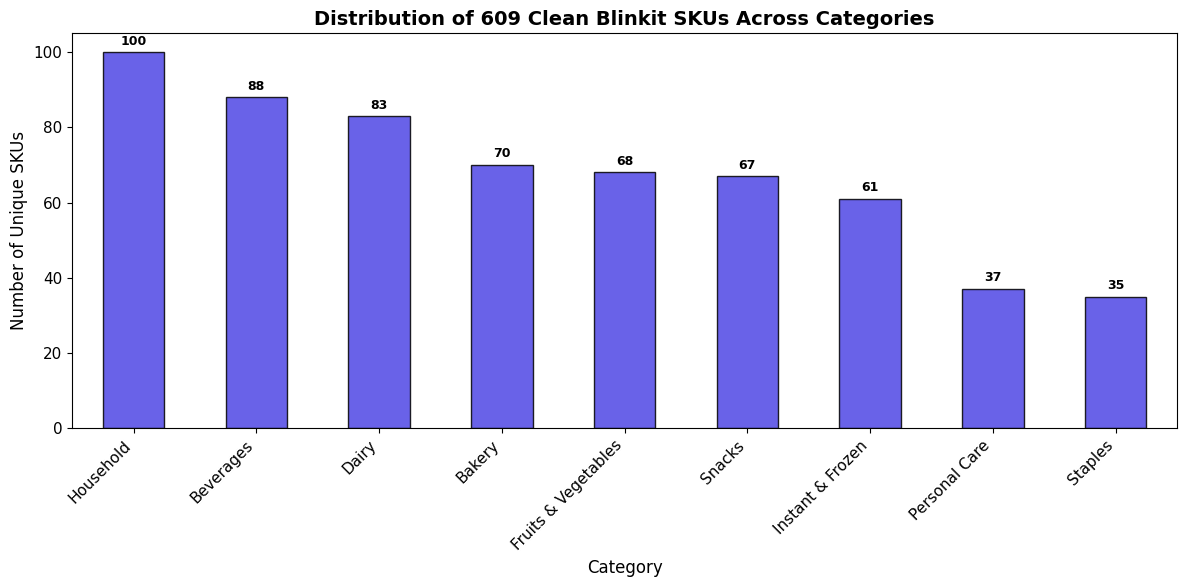

In [5]:
cat_counts = df['category'].value_counts()

plt.figure(figsize=(12, 6))
ax = cat_counts.plot(kind='bar', color='#4f46e5', edgecolor='black', alpha=0.85)
plt.title('Distribution of 609 Clean Blinkit SKUs Across Categories', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Number of Unique SKUs', fontsize=12)
plt.xticks(rotation=45, ha='right')
for i, v in enumerate(cat_counts):
    ax.text(i, v + 2, str(v), ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

### Stage 1 Audit Takeaways:
1. **Zero Nulls:** All 609 SKUs have complete identifiers, category classifications, and pricing.
2. **Zero Price Violations:** 100% of SKUs comply with statutory `selling_price <= MRP`.
3. **Coverage:** Dairy & Beverages (95 SKUs) and Snacks (78 SKUs) represent the highest assortment depth.